# Unequal-arm TDI noise: inference in the frequency (FD) and WDM domains

Companion notebook of `paper/main.tex`.  We infer the two amplitudes of the LISA
instrumental noise — test-mass acceleration $A$ and optical-metrology $P$ — from
TDI-2 Michelson data, in the frequency domain (FD) and in the
Wilson–Daubechies–Meyer (WDM) time-frequency domain.

* **Analysis 1** — equilateral, static constellation: stationary noise, the
  standard diagonal $AET$ model is exact.  FD and WDM must give the same posterior.
* **Analysis 2** — realistic (ESA trailing) orbits: unequal, time-varying arms,
  non-stationary noise with correlated channels.  WDM uses the closed-form
  covariance of `main.tex` *locally in time*; FD can only use a stationary model
  (time-averaged, or frozen at one epoch), or the exact dense covariance.
* **Analysis 3** — same data, FD fitted with the standard equal-arm diagonal
  $AET$ model, as commonly done.

Pipeline (all "standard setup"): link noises drawn from our PSDs in the frequency
domain → intermediary variables $\eta_{ij}=N_{ij}+a_{ij}+\mathcal D_{ij}a_{ji}$ →
`pytdi` TDI-2 $X_2,Y_2,Z_2$ with light travel times from `lisaorbits` → FD
(`numpy.fft`) and WDM (`wdm_transform`) → coarse-grained Wishart likelihoods in
`jax` → `jexplore` ensemble MCMC.  The code lives in `aet_wdm.py`.

In [1]:
import json
import os
import time
import warnings

import numpy as np
import jax
import jax.numpy as jnp
import matplotlib as mpl
import matplotlib.pyplot as plt
import corner
from scipy.interpolate import CubicSpline

import aet_wdm as aw

warnings.filterwarnings("ignore", message=".*preferred interpolation.*")
from lisaorbits import OEMOrbits  # noqa: E402

HERE = os.path.abspath(os.getcwd())
DATA = os.path.join(HERE, "data")
RES = os.path.join(HERE, "results")
FIG = os.path.abspath(os.path.join(HERE, "..", "paper", "figures"))
for p in (DATA, RES, FIG):
    os.makedirs(p, exist_ok=True)
REGENERATE = False          # set True to redraw the noise realisations

# Validated categorical slots (dataviz reference palette, light mode), fixed order:
# 1 blue = WDM, 2 orange = FD, 3 aqua = third model / control.
COL = {"wdm": "#2a78d6", "fd": "#eb6834", "ctl": "#1baf7a", "ink": "#52514e", "grid": "#e1e0d9"}
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10, "axes.titlesize": 10,
    "axes.labelsize": 10, "legend.fontsize": 8.5, "axes.edgecolor": "#c3c2b7",
    "axes.linewidth": 0.8, "xtick.color": COL["ink"], "ytick.color": COL["ink"],
    "axes.labelcolor": "#0b0b0b", "axes.grid": True, "grid.color": COL["grid"],
    "grid.linewidth": 0.6, "lines.linewidth": 1.6, "legend.frameon": False,
})

print("jax", jax.__version__, jax.devices())

/home/giorgio/miniconda3/envs/globalfit/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


jax 0.10.0 [CpuDevice(id=0)]


## 0. Grid, noise model, closed-form covariance

One year of data at $\Delta t_s=10$ s, $N = n_t n_f = 3072\times1024$ samples.
The WDM tiling has $n_f=1024$ bands of width $\Delta F = 1/(2 n_f\Delta t_s)=48.8\,\mu$Hz
and $n_t=3072$ time bins of $\Delta T=n_f\Delta t_s=2.84$ h.  The analysis band is
WDM bands $m=2\dots512$, i.e. $0.1$–$25$ mHz.

**Coarse graining.** Both likelihoods are evaluated on the *same* log-spaced
frequency cells; the WDM plane is further cut into 48 time cells (≈7.6 days).  Within
a cell the averaged outer products of the data are Wishart distributed — complex
Wishart for the DFT bins, real Wishart for the WDM coefficients — and the model is
the exact cell average of the covariance.  Since the covariance is linear in
$A^2$ and $P^2$, the unit-amplitude surfaces are precomputed once.

In [2]:
grid = aw.Grid(dt=10.0, nt=3072, nf=1024)
M_LO, M_HI, N_FCELL, N_TCELL, EDGE = 2, 512, 100, 48, 12
medges = aw.log_edges(M_LO, M_HI, N_FCELL)
print(f"N = {grid.n}  T = {grid.T/86400:.1f} d   WDM: dT = {grid.delta_t/3600:.2f} h, "
      f"dF = {grid.delta_f*1e6:.1f} uHz   band {M_LO*grid.delta_f*1e3:.3f}-{M_HI*grid.delta_f*1e3:.2f} mHz")
print(f"{len(medges)-1} frequency cells, {N_TCELL} time cells")
L_EQ = aw.L_NOMINAL / aw.C_LIGHT
THETA_TRUE = np.array([aw.A_TRUE, aw.P_TRUE])
PRIOR_LO, PRIOR_HI = np.array([0.1, 0.1]), np.array([100.0, 100.0])

N = 3145728  T = 364.1 d   WDM: dT = 2.84 h, dF = 48.8 uHz   band 0.098-25.00 mHz
76 frequency cells, 48 time cells


**Check of the closed form.**  `aet_wdm.tdi2_geometry` implements the exact
covariance of `main.tex` (Sec. "Exact covariance"), generalised to TDI 2
($X_2=(1-\mathcal D_{12}\mathcal D_{21}\mathcal D_{13}\mathcal D_{31})X_1$ for frozen delays)
and to unequal up/down links.  We compare it with a brute-force transfer matrix
built from the pytdi delay polynomials themselves.

In [3]:
orb = OEMOrbits.from_included("esa-trailing")
T_START = orb.t_init + 10 * 86400.0
ltt_esa = lambda t: orb.compute_ltt(T_START + np.asarray(t))

fchk = np.geomspace(1e-4, 0.03, 300)
for name, d in [("equal arms", np.full(6, L_EQ)), ("ESA, t = 0", ltt_esa(np.array([0.0]))[0]),
                ("ESA, t = T/2", ltt_esa(np.array([grid.T / 2]))[0])]:
    M = aw.pytdi_transfer_matrix(fchk, d)
    S = np.concatenate([np.tile(aw.psd_oms_unit(fchk)[:, None], (1, 6)) * aw.P_TRUE**2,
                        np.tile(aw.psd_tm_unit(fchk)[:, None], (1, 6)) * aw.A_TRUE**2], 1)
    Cbf = np.einsum("fci,fi,fdi->fcd", M, S, M.conj())
    utm, uoms = aw.tdi2_unit_cov(fchk, d)
    Ccf = aw.A_TRUE**2 * utm + aw.P_TRUE**2 * uoms
    dg = np.abs(np.einsum("fii->fi", Cbf))
    err = np.max(np.abs(Cbf - Ccf) / np.sqrt(dg[:, :, None] * dg[:, None, :]))
    print(f"{name:14s}: max |C_pytdi - C_closed| / sqrt(C_ii C_jj) = {err:.1e}")

OEM preferred interpolation method ignored, using spline interpolation (see InterpolatedOrbits for details)


equal arms    : max |C_pytdi - C_closed| / sqrt(C_ii C_jj) = 7.1e-13
ESA, t = 0    : max |C_pytdi - C_closed| / sqrt(C_ii C_jj) = 9.6e-13
ESA, t = T/2  : max |C_pytdi - C_closed| / sqrt(C_ii C_jj) = 8.4e-13


**Orbits.**  Arm deviations $\epsilon_k(t) = \bar L_k(t)/\bar L - 1$ of the ESA
trailing orbits over our year, and the two "quadrupole" combinations of
`main.tex` (Sec. "general case") that break the $S_3$ symmetry:
$\epsilon_{(1)}=(\epsilon_1-\epsilon_2)/\sqrt2$, $\epsilon_{(2)}=(\epsilon_1+\epsilon_2-2\epsilon_3)/\sqrt6$.

max |eps_k| = 0.014301271465356313   quadrupole rms = 0.007793041539733789   link asymmetry max = 0.0008395038500097485 s


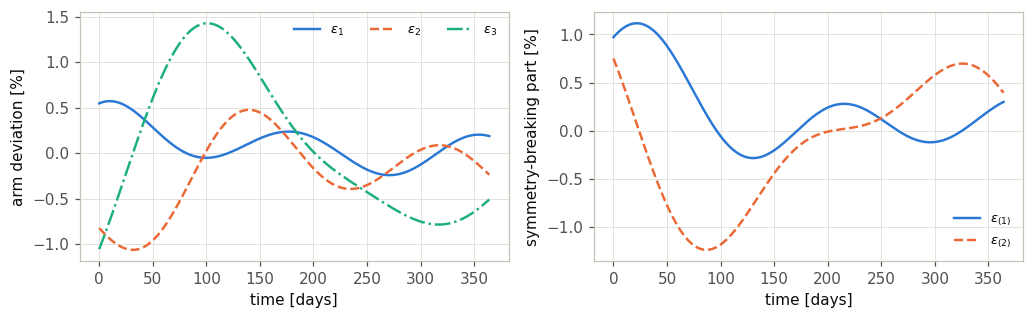

In [4]:
tday = np.linspace(0, grid.T, 2000)
lt = ltt_esa(tday)
lbar, delta = aw.arm_quantities(lt)
eps = lbar / lbar.mean() - 1
eq1 = (eps[:, 0] - eps[:, 1]) / np.sqrt(2)
eq2 = (eps[:, 0] + eps[:, 1] - 2 * eps[:, 2]) / np.sqrt(6)
print("max |eps_k| =", np.abs(eps).max(), "  quadrupole rms =", np.sqrt(np.mean(eq1**2 + eq2**2)),
      "  link asymmetry max =", np.abs(delta).max(), "s")

fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.0))
for k, c, ls in zip(range(3), (COL["wdm"], COL["fd"], COL["ctl"]), ("-", "--", "-.")):
    ax[0].plot(tday / 86400, 1e2 * eps[:, k], color=c, ls=ls, label=fr"$\epsilon_{k+1}$")
ax[0].set_xlabel("time [days]"); ax[0].set_ylabel(r"arm deviation [%]"); ax[0].legend(ncol=3)
ax[1].plot(tday / 86400, 1e2 * eq1, color=COL["wdm"], label=r"$\epsilon_{(1)}$")
ax[1].plot(tday / 86400, 1e2 * eq2, color=COL["fd"], ls="--", label=r"$\epsilon_{(2)}$")
ax[1].set_xlabel("time [days]"); ax[1].set_ylabel("symmetry-breaking part [%]"); ax[1].legend()
fig.tight_layout(); fig.savefig(os.path.join(FIG, "orbits_eps.pdf"))
plt.show()

## Helpers: posterior plots and bookkeeping

In [5]:
SUMMARY = {}


def fit(name, loglik, x0=THETA_TRUE, niters=3000, burn=1000, nwalker=32, seed=7):
    """MAP + jexplore run; stores posterior summary and timings."""
    t0 = time.perf_counter()
    xmap, cov = aw.find_map(loglik, x0)
    t_map = time.perf_counter() - t0
    samples, info = aw.run_mcmc(loglik, PRIOR_LO, PRIOR_HI, xmap, cov, nwalker=nwalker,
                                niters=niters, burn=burn, seed=seed)
    t_eval = aw.time_loglik(loglik, xmap, nwalker=nwalker)
    s = aw.summary(samples)
    SUMMARY[name] = dict(mean=s["mean"].tolist(), std=s["std"].tolist(),
                         bias_sigma=s["bias_sigma"].tolist(), rel_bias=s["rel_bias"].tolist(),
                         map=xmap.tolist(), laplace_std=np.sqrt(np.diag(cov)).tolist(),
                         t_eval_ms=1e3 * t_eval, t_mcmc_s=info["wall"], acceptance=info["acceptance"],
                         acl=info["acl"], nsamples=int(samples.shape[0]))
    print(f"{name:28s} A = {s['mean'][0]:.4f} ± {s['std'][0]:.4f}  P = {s['mean'][1]:.4f} ± {s['std'][1]:.4f}"
          f"   bias/σ = ({s['bias_sigma'][0]:+6.2f}, {s['bias_sigma'][1]:+6.2f})"
          f"   eval {1e3*t_eval:6.2f} ms / {nwalker} walkers, MCMC {info['wall']:5.1f} s,"
          f" acc {info['acceptance']:.2f}, acl {info['acl']:.0f}")
    return samples


def corner_overlay(runs, fname, title=None, ranges=None, bins=40, show=True):
    """Overlay posteriors ``runs = [(samples, label, color, linestyle), ...]``."""
    fig = None
    lv = (1 - np.exp(-0.5), 1 - np.exp(-2.0))            # 1 and 2 sigma in 2D
    if ranges is None:                                   # common range for all runs
        allr = np.concatenate([r[0] for r in runs])
        lo, hi = np.percentile(allr, 0.05, axis=0), np.percentile(allr, 99.95, axis=0)
        pad = 0.08 * (hi - lo)
        ranges = [(lo[i] - pad[i], hi[i] + pad[i]) for i in range(2)]
    for s, lab, c, ls in runs:
        fig = corner.corner(s, fig=fig, color=c, bins=bins, smooth=1.0, smooth1d=1.0,
                            weights=np.full(len(s), 1.0 / len(s)),
                            levels=lv, plot_datapoints=False, plot_density=False,
                            fill_contours=False, range=ranges,
                            hist_kwargs=dict(lw=1.4, ls=ls),
                            contour_kwargs=dict(linewidths=1.4, linestyles=ls),
                            labels=aw.PARAM_LABELS, label_kwargs=dict(fontsize=10))
    ndim = len(THETA_TRUE)
    for i in range(ndim):                                 # rescale 1-d panels to the tallest curve
        axd = fig.axes[i * ndim + i]
        ymax = max((np.max(l.get_ydata()) for l in axd.get_lines() if len(l.get_ydata())), default=None)
        if ymax:
            axd.set_ylim(0, 1.1 * ymax)
    corner.overplot_lines(fig, THETA_TRUE, color="#0b0b0b", lw=0.9, ls=":")
    corner.overplot_points(fig, THETA_TRUE[None], marker="+", color="#0b0b0b", ms=8)
    handles = [mpl.lines.Line2D([], [], color=c, ls=ls, lw=1.6, label=lab) for _, lab, c, ls in runs]
    handles.append(mpl.lines.Line2D([], [], color="#0b0b0b", ls=":", lw=0.9, label="injected"))
    fig.legend(handles=handles, loc="upper right", bbox_to_anchor=(0.98, 0.98), fontsize=9)
    if title:
        fig.suptitle(title, x=0.02, ha="left", fontsize=10)
    fig.set_size_inches(5.6, 5.2)
    fig.savefig(os.path.join(FIG, fname), bbox_inches="tight")
    if show:
        plt.show()
    return fig


def cached(fname, fn):
    """Load ``DATA/fname`` (npz) or compute ``fn() -> dict`` and save it."""
    path = os.path.join(DATA, fname)
    if os.path.exists(path) and not REGENERATE:
        with np.load(path) as z:
            return {k: z[k] for k in z.files}
    out = fn()
    np.savez(path, **out)
    return out

## 1. Analysis 1 — equilateral constellation, stationary noise

Six equal, constant light travel times $L/c = 8.339$ s.  The link noises are drawn
periodic and extended periodically before TDI, so $X_2,Y_2,Z_2$ are exactly the
circular TDI of a stationary process: no window is needed in FD and no WDM
time bin is lost.  In this case $AET$ diagonalise the covariance exactly
(`main.tex`, Sec. "equilateral case"), so both domains use the diagonal
model $S_A=S_E$, $S_T$.

In [6]:
def gen_equal():
    t0 = time.perf_counter()
    xyz = aw.simulate_tdi2(np.random.default_rng(101), grid.n, grid.dt, aw.A_TRUE, aw.P_TRUE,
                           np.full(6, L_EQ), periodic=True)
    print(f"simulated equal-arm data in {time.perf_counter()-t0:.0f} s")
    return dict(xyz=xyz)


xyz1 = cached("data_equal_arm.npz", gen_equal)["xyz"]
cells1 = aw.Cells(grid, medges, np.round(np.linspace(0, grid.nt, N_TCELL + 1)).astype(int))

I1, K1 = aw.fd_periodograms(xyz1, grid, cells1)                 # FD, no window
W1 = aw.wdm_transform(xyz1, grid)
Y1, D1 = aw.wdm_cells(W1, cells1)
fd_eq_tm, fd_eq_oms = aw.fd_model_equal_arm(cells1, L_EQ)
wd_eq_tm, wd_eq_oms = aw.wdm_model_equal_arm(cells1, L_EQ)

# consistency of the data with the model (normalised residuals ~ N(0,1))
C_fd = aw.A_TRUE**2 * fd_eq_tm + aw.P_TRUE**2 * fd_eq_oms
C_wd = aw.A_TRUE**2 * wd_eq_tm + aw.P_TRUE**2 * wd_eq_oms
z_fd = (np.real(np.einsum("cii->ci", I1)) / C_fd - 1) * np.sqrt(K1)[:, None]
z_wd = (np.einsum("tcii->tci", Y1) / C_wd[None] - 1) * np.sqrt(D1 / 2)[..., None]
print("FD  residuals (A,E,T): mean", z_fd.mean(0).round(2), " std", z_fd.std(0).round(2))
print("WDM residuals (A,E,T): mean", z_wd.mean((0, 1)).round(2), " std", z_wd.std((0, 1)).round(2))

ll1_fd = aw.make_loglik_diag(I1, K1, fd_eq_tm, fd_eq_oms, complex_data=True)
ll1_wd = aw.make_loglik_diag(Y1, D1, wd_eq_tm[None], wd_eq_oms[None], complex_data=False)
s1_fd = fit("A1: FD, diagonal AET", ll1_fd)
s1_wd = fit("A1: WDM, diagonal AET", ll1_wd)

FD  residuals (A,E,T): mean [0.16 0.15 0.13]  std [1.01 1.19 0.97]
WDM residuals (A,E,T): mean [0.02 0.02 0.02]  std [1.03 1.03 1.02]


A1: FD, diagonal AET         A = 3.0047 ± 0.0042  P = 15.0077 ± 0.0053   bias/σ = ( +1.14,  +1.44)   eval   0.05 ms / 32 walkers, MCMC   2.5 s, acc 0.68, acl 18


A1: WDM, diagonal AET        A = 3.0047 ± 0.0042  P = 15.0074 ± 0.0053   bias/σ = ( +1.13,  +1.41)   eval   0.57 ms / 32 walkers, MCMC   2.4 s, acc 0.68, acl 19


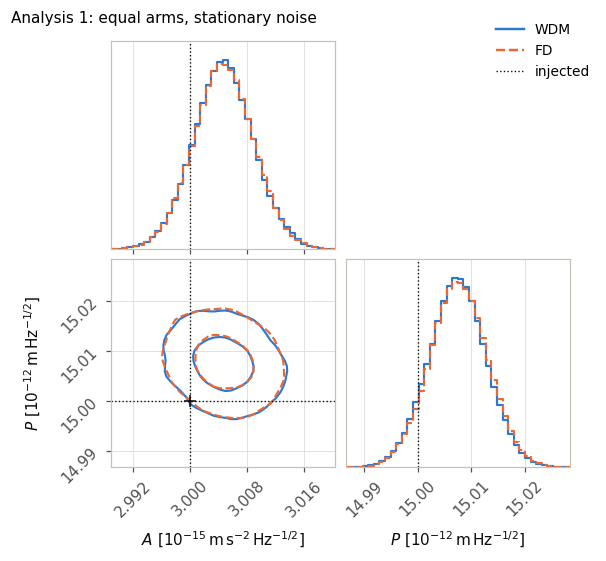

WDM - FD posterior means in units of sigma: [-0.00397761 -0.04383442]
sigma ratio WDM/FD: [0.99981295 0.99255993]


In [7]:
corner_overlay([(s1_wd, "WDM", COL["wdm"], "-"), (s1_fd, "FD", COL["fd"], "--")],
               "corner_analysis1.pdf", title="Analysis 1: equal arms, stationary noise")
d = (np.array(SUMMARY["A1: WDM, diagonal AET"]["mean"]) - np.array(SUMMARY["A1: FD, diagonal AET"]["mean"]))
print("WDM - FD posterior means in units of sigma:", d / np.array(SUMMARY["A1: FD, diagonal AET"]["std"]))
print("sigma ratio WDM/FD:", np.array(SUMMARY["A1: WDM, diagonal AET"]["std"]) / np.array(SUMMARY["A1: FD, diagonal AET"]["std"]))

**Is the agreement (and the ~1σ offset from the injection) generic?**  The script
`mc_bias_check.py` repeats Analysis 1 on independent noise realisations (maximum-likelihood
points and Laplace errors, same models).  Over realisations the normalised errors must have mean
0 and scatter 1, and FD and WDM must agree realisation by realisation.

In [8]:
mc = []
for fn in ("mc_bias_check.json", "mc_bias_check_40.json"):
    path = os.path.join(RES, fn)
    if os.path.exists(path):
        mc += json.load(open(path))["per_real"]
if mc:
    fdz = np.array([m["fd"] for m in mc]); wdz = np.array([m["wdm"] for m in mc]); dz = np.array([m["diff"] for m in mc])
    MC = dict(nreal=len(mc), fd_mean=fdz.mean(0).tolist(), fd_scatter=fdz.std(0, ddof=1).tolist(),
              wdm_mean=wdz.mean(0).tolist(), wdm_scatter=wdz.std(0, ddof=1).tolist(),
              diff_mean=dz.mean(0).tolist(), diff_scatter=dz.std(0, ddof=1).tolist(),
              resid_std_fd=np.mean([m["zstd_fd"] for m in mc if "zstd_fd" in m], 0).tolist(),
              resid_std_wdm=np.mean([m["zstd_wdm"] for m in mc if "zstd_wdm" in m], 0).tolist())
    print(f"{len(mc)} realisations (A, P):")
    print("  FD  (MLE - truth)/sigma: mean", np.round(MC["fd_mean"], 2), " scatter", np.round(MC["fd_scatter"], 2),
          f"  [expected 0 ± {1/np.sqrt(len(mc)):.2f}, 1 ± {1/np.sqrt(2*len(mc)):.2f}]")
    print("  WDM (MLE - truth)/sigma: mean", np.round(MC["wdm_mean"], 2), " scatter", np.round(MC["wdm_scatter"], 2))
    print("  (WDM - FD)/sigma       : mean", np.round(MC["diff_mean"], 3), " scatter", np.round(MC["diff_scatter"], 3))
    print("  residual std per channel (A,E,T): FD", np.round(MC["resid_std_fd"], 3), " WDM", np.round(MC["resid_std_wdm"], 3))
else:
    MC = {}
    print("run `python mc_bias_check.py` first to produce results/mc_bias_check.json")

52 realisations (A, P):
  FD  (MLE - truth)/sigma: mean [ 0.12 -0.09]  scatter [0.87 1.14]   [expected 0 ± 0.14, 1 ± 0.10]
  WDM (MLE - truth)/sigma: mean [ 0.12 -0.09]  scatter [0.87 1.13]
  (WDM - FD)/sigma       : mean [0.002 0.004]  scatter [0.045 0.032]
  residual std per channel (A,E,T): FD [0.986 0.984 1.008]  WDM [1.004 1.002 1.01 ]


## 2. Analysis 2 — realistic (ESA trailing) orbits

Same noise amplitudes, but the delays are the six light travel times of the ESA
trailing orbits, varying over the year.  The noise is now **non-stationary** and
the channels are **correlated**.  FD data are tapered with a Tukey window (1-day
cosine ramps).  The same tapered series is WDM-transformed, and the first and last
12 WDM time bins (the taper plus a margin) are discarded: without the taper the jump
between the end and the start of the non-periodic series leaks into the null channel,
which at 0.1 mHz is ~10^3 times weaker than X in amplitude (the jump is not).

Models:
* **WDM, local** — pixel covariance = window-averaged real part of the closed-form
  frozen-arm covariance, evaluated with the arms at the time of the WDM bin (3×3
  per cell, time dependent).
* **FD, time-averaged** — the exact expectation of the FD periodogram,
  $\sum_t w_t^2 C(f,t)/\sum_t w_t^2$ (3×3 per bin); it ignores the correlations
  between different frequencies induced by the time variation.
* **FD, frozen** — the closed-form covariance with the arms frozen at mid-year: the
  analytical approximation of `main.tex` used "as is" in FD.

In [9]:
def gen_esa():
    t0 = time.perf_counter()
    xyz = aw.simulate_tdi2(np.random.default_rng(202), grid.n, grid.dt, aw.A_TRUE, aw.P_TRUE, ltt_esa)
    print(f"simulated ESA-orbit data in {time.perf_counter()-t0:.0f} s")
    return dict(xyz=xyz)


xyz2 = cached("data_esa_orbits.npz", gen_esa)["xyz"]
cells2 = aw.Cells(grid, medges, np.round(np.linspace(EDGE, grid.nt - EDGE, N_TCELL + 1)).astype(int))
window = aw.tukey(grid.n, int(86400 / grid.dt))
tnodes = np.linspace(-2 * 86400, grid.T + 2 * 86400, 151)       # orbit sampling for the model

I2, K2 = aw.fd_periodograms(xyz2, grid, cells2, window=window)
W2 = aw.wdm_transform(xyz2 * window, grid)
Y2, D2 = aw.wdm_cells(W2, cells2)


def surfaces_esa():
    t0 = time.perf_counter()
    nodes = aw.wdm_band_nodes(cells2, ltt_esa, tnodes)
    t1 = time.perf_counter()
    ftm, foms = aw.fd_model_timeavg(cells2, ltt_esa, tnodes, window=window)
    t2 = time.perf_counter()
    d_mid = ltt_esa(np.array([grid.T / 2]))[0]
    zt, zo = aw.fd_model_static(cells2, d_mid)
    print(f"model surfaces: WDM band averages at {tnodes.size} orbit epochs {t1-t0:.0f} s,"
          f" FD time-averaged {t2-t1:.0f} s")
    return dict(fd_tm=ftm, fd_oms=foms, fz_tm=zt, fz_oms=zo, nodes_tm=nodes[0], nodes_oms=nodes[1])


surf = cached("surfaces_esa.npz", surfaces_esa)
# time-local WDM surfaces: cubic-spline interpolation of the epochs to every WDM bin, cell averages
surf["wdm_tm"], surf["wdm_oms"] = aw.wdm_model_local(cells2, ltt_esa, tnodes,
                                                     nodes=(surf["nodes_tm"], surf["nodes_oms"]))

C_loc = aw.A_TRUE**2 * surf["wdm_tm"] + aw.P_TRUE**2 * surf["wdm_oms"]
C_avg = aw.A_TRUE**2 * surf["fd_tm"] + aw.P_TRUE**2 * surf["fd_oms"]
z_fd = (np.real(np.einsum("cii->ci", I2)) / np.real(np.einsum("cii->ci", C_avg)) - 1) * np.sqrt(K2)[:, None]
z_wd = (np.einsum("tcii->tci", Y2) / np.einsum("tcii->tci", C_loc) - 1) * np.sqrt(D2 / 2)[..., None]
print("FD  (time-avg) residuals (A,E,T): mean", z_fd.mean(0).round(2), " std", z_fd.std(0).round(2))
print("WDM (local)    residuals (A,E,T): mean", z_wd.mean((0, 1)).round(2), " std", z_wd.std((0, 1)).round(2))
for a, b in [(0, 1), (0, 2), (1, 2)]:
    rm = C_loc[..., a, b] / np.sqrt(C_loc[..., a, a] * C_loc[..., b, b])
    rd = Y2[..., a, b] / np.sqrt(C_loc[..., a, a] * C_loc[..., b, b])
    zz = (rd - rm) * np.sqrt(D2)
    print(f"WDM local correlation {'AET'[a]}{'AET'[b]}: max |rho_model| = {np.abs(rm).max():.3f},"
          f" residual z: mean {zz.mean():+.2f} std {zz.std():.2f}")

FD  (time-avg) residuals (A,E,T): mean [-0.03  0.17 -0.09]  std [1.11 1.   0.97]
WDM (local)    residuals (A,E,T): mean [-0.    0.03 -0.  ]  std [1.   0.99 1.  ]
WDM local correlation AE: max |rho_model| = 0.020, residual z: mean -0.01 std 1.03
WDM local correlation AT: max |rho_model| = 0.996, residual z: mean +0.02 std 1.04
WDM local correlation ET: max |rho_model| = 0.998, residual z: mean -0.01 std 1.04


In [10]:
ll2_wd = aw.make_loglik_full(Y2, D2, surf["wdm_tm"], surf["wdm_oms"], complex_data=False)
ll2_fd = aw.make_loglik_full(I2, K2, surf["fd_tm"], surf["fd_oms"], complex_data=True)
ll2_fz = aw.make_loglik_full(I2, K2, surf["fz_tm"], surf["fz_oms"], complex_data=True)
s2_wd = fit("A2: WDM, local 3x3", ll2_wd)
s2_fd = fit("A2: FD, time-averaged 3x3", ll2_fd)
s2_fz = fit("A2: FD, frozen arms 3x3", ll2_fz)

A2: WDM, local 3x3           A = 2.9995 ± 0.0041  P = 15.0059 ± 0.0054   bias/σ = ( -0.11,  +1.09)   eval   0.23 ms / 32 walkers, MCMC   1.8 s, acc 0.68, acl 20


A2: FD, time-averaged 3x3    A = 2.9983 ± 0.0039  P = 15.0052 ± 0.0054   bias/σ = ( -0.44,  +0.96)   eval   0.06 ms / 32 walkers, MCMC   0.9 s, acc 0.68, acl 18


A2: FD, frozen arms 3x3      A = 2.6636 ± 0.0039  P = 18.4188 ± 0.0064   bias/σ = (-85.66, +533.81)   eval   0.07 ms / 32 walkers, MCMC   1.0 s, acc 0.68, acl 19


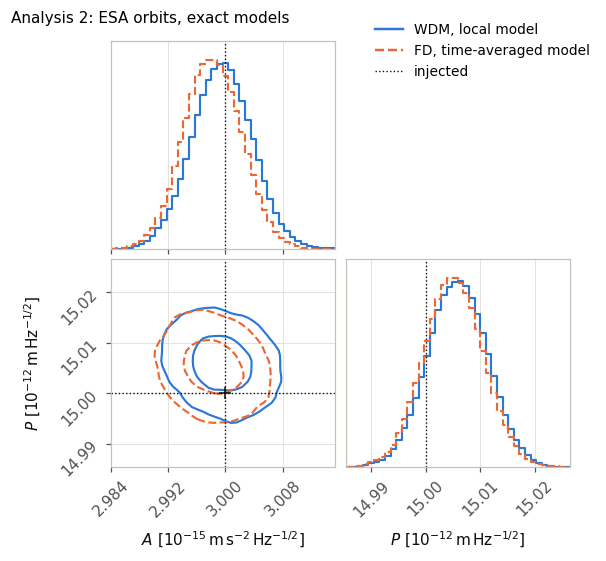

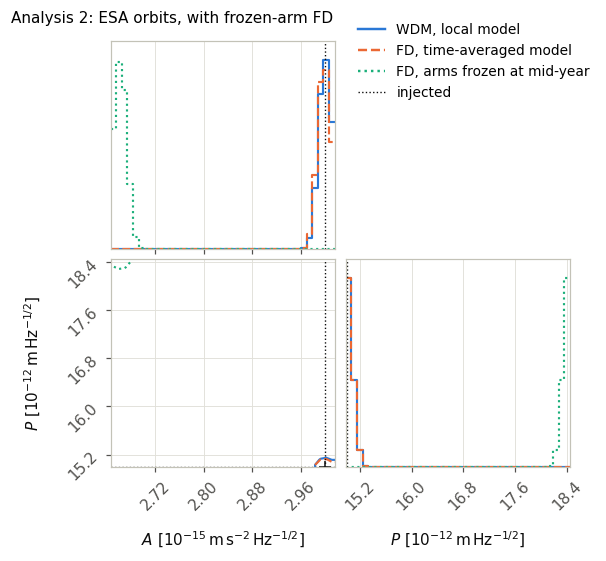

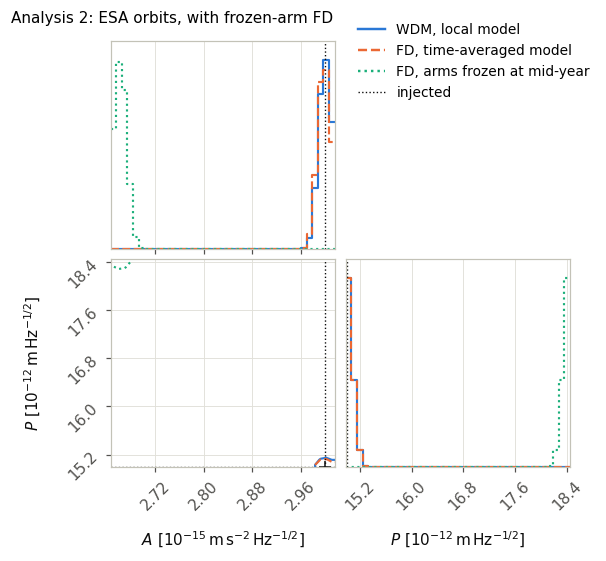

In [11]:
corner_overlay([(s2_wd, "WDM, local model", COL["wdm"], "-"),
                (s2_fd, "FD, time-averaged model", COL["fd"], "--")],
               "corner_analysis2.pdf", title="Analysis 2: ESA orbits, exact models")
lo_ = np.minimum(s2_fz.min(0), s2_wd.min(0)); hi_ = np.maximum(s2_fz.max(0), s2_wd.max(0))
corner_overlay([(s2_wd, "WDM, local model", COL["wdm"], "-"),
                (s2_fd, "FD, time-averaged model", COL["fd"], "--"),
                (s2_fz, "FD, arms frozen at mid-year", COL["ctl"], ":")],
               "corner_analysis2_frozen.pdf", title="Analysis 2: ESA orbits, with frozen-arm FD",
               ranges=[(lo_[0], hi_[0]), (lo_[1], hi_[1])])

### 2b. Why FD would need the full covariance: correlations between frequencies

For a locally stationary process the normalised DFT bins satisfy
$\langle x_k x_{k-q}^\dagger\rangle = \hat C_q(\bar f) = \sum_n \frac{w_n^2}{\sum w^2}\,C(\bar f,t_n)\,e^{-2\pi i qn/N}$:
the time variation of the arms correlates bins at lag $q$ with the $q$-th Fourier
coefficient of $C(f,t)$ over the observation.  We compute $|\hat C_q|/\hat C_0$ from the
closed-form model and check it against the data (average of $x_k x^*_{k-q}$ over a band).
The WDM pixels, instead, only see the variation of the arms within one atom.

0.1–0.2 mHz  |C_q|/C_0 model (q=1..3), A E T: [[0.0102, 0.011, 0.5995], [0.0058, 0.0048, 0.2017], [0.0035, 0.0036, 0.0517]]
             data estimate         : [[0.0084, 0.0379, 0.5506], [0.0246, 0.0226, 0.1606], [0.0356, 0.0244, 0.023]] (noise ~ 0.0179)


1–2 mHz  |C_q|/C_0 model (q=1..3), A E T: [[0.0101, 0.011, 0.086], [0.0058, 0.0048, 0.0292], [0.0035, 0.0036, 0.0093]]
         data estimate         : [[0.0056, 0.0151, 0.0816], [0.0081, 0.0117, 0.0219], [0.005, 0.0037, 0.0165]] (noise ~ 0.0056)


10–20 mHz  |C_q|/C_0 model (q=1..3), A E T: [[0.0053, 0.0058, 0.0092], [0.004, 0.0038, 0.0049], [0.0035, 0.0034, 0.0036]]
           data estimate         : [[0.0055, 0.0053, 0.0093], [0.0027, 0.0049, 0.0048], [0.0064, 0.0041, 0.0046]] (noise ~ 0.0018)
WDM neighbour-pixel correlation (A,E,T): time [-0.0004  0.0001  0.0013]  frequency [-0.0003 -0.0005 -0.0006]  (noise ~ 0.0008)


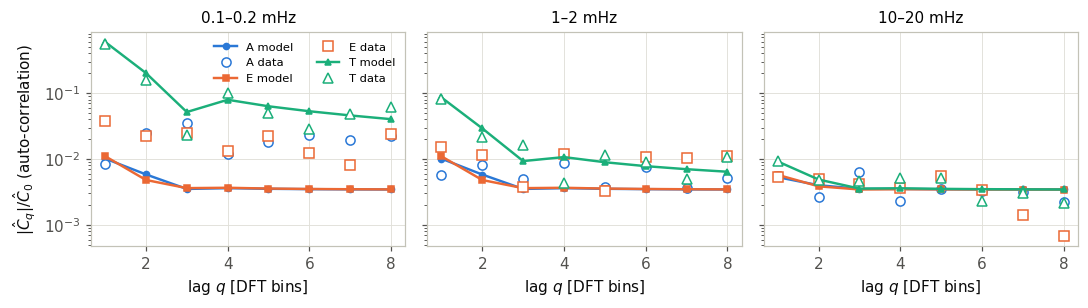

In [12]:
qs = np.arange(0, 9)
omq = aw.cyclic_weights(tnodes, grid, window, qs)
dn = np.asarray(ltt_esa(tnodes))
aet2 = np.einsum("ai,in->an", aw.R_AET, xyz2)
Xf2 = np.fft.rfft(aet2 * window, axis=-1) * np.sqrt(2 * grid.dt / np.sum(window**2))
bands = {"0.1–0.2 mHz": (1e-4, 2e-4), "1–2 mHz": (1e-3, 2e-3), "10–20 mHz": (1e-2, 2e-2)}
corr_model, corr_data = {}, {}
for bname, (fa, fb) in bands.items():
    ka, kb = int(fa / grid.df), int(fb / grid.df)
    fsub = np.arange(ka, kb, 50) * grid.df
    ctm, coms = aw.fd_cyclic_spectrum(fsub, dn, omq)
    cq = aw.A_TRUE**2 * ctm + aw.P_TRUE**2 * coms          # (q, f, 3, 3)
    cm = np.abs(np.einsum("qfii->qfi", cq)) / np.real(np.einsum("fii->fi", cq[0]))[None]
    corr_model[bname] = cm.mean(1)                        # (q, 3)
    kk = np.arange(ka + qs.max(), kb)
    c0tm, c0oms = aw.fd_cyclic_spectrum(kk * grid.df, dn, omq[:1])
    c0 = np.real(np.einsum("fii->fi", aw.A_TRUE**2 * c0tm[0] + aw.P_TRUE**2 * c0oms[0]))
    cd = []
    for q in qs:
        prod = Xf2[:, kk] * np.conj(Xf2[:, kk - q])
        cd.append(np.abs(np.mean(prod / c0.T, axis=1)))
    corr_data[bname] = np.array(cd)                       # (q, 3)
    print(bname, " |C_q|/C_0 model (q=1..3), A E T:", np.round(corr_model[bname][1:4], 4).tolist())
    print(" " * len(bname), " data estimate         :", np.round(corr_data[bname][1:4], 4).tolist(),
          f"(noise ~ {1/np.sqrt(kk.size):.4f})")

# WDM: correlation between neighbouring time pixels of the same band (data)
Wa = W2[:, EDGE:grid.nt - EDGE, M_LO:M_HI + 1]
wn = Wa / np.sqrt(np.mean(Wa**2, axis=1, keepdims=True))
rho_n = np.mean(wn[:, 1:, :] * wn[:, :-1, :], axis=(1, 2))
rho_m = np.mean(wn[:, :, 1:] * wn[:, :, :-1], axis=(1, 2))
print("WDM neighbour-pixel correlation (A,E,T): time", rho_n.round(4), " frequency", rho_m.round(4),
      f" (noise ~ {1/np.sqrt(wn[0].size):.4f})")

fig, ax = plt.subplots(1, 3, figsize=(10, 2.9), sharey=True)
for i, (bname, cm) in enumerate(corr_model.items()):
    for c, ch, mk in zip((COL["wdm"], COL["fd"], COL["ctl"]), "AET", ("o", "s", "^")):
        ax[i].plot(qs[1:], cm[1:, "AET".index(ch)], color=c, marker=mk, ms=4, label=f"{ch} model")
        ax[i].plot(qs[1:], corr_data[bname][1:, "AET".index(ch)], color=c, ls="none", marker=mk,
                   mfc="white", ms=6, label=f"{ch} data")
    ax[i].set_yscale("log"); ax[i].set_title(bname); ax[i].set_xlabel("lag $q$ [DFT bins]")
ax[0].set_ylabel(r"$|\hat C_q|/\hat C_0$ (auto-correlation)")
ax[0].legend(ncol=2, fontsize=7.5)
fig.tight_layout(); fig.savefig(os.path.join(FIG, "fd_bin_correlations.pdf")); plt.show()

### 2c. Cost of the exact FD likelihood vs WDM

The exact FD likelihood needs the dense $3K\times3K$ covariance of the $K$ DFT bins of
the band.  We build it on sub-bands of increasing size from $\hat C_q$ ($|q|\le 8$) and
time a Cholesky solve, then extrapolate the $O(K^3)$ scaling to the full band.

K =   128 bins (matrix 384x384):      2.21 ms per evaluation


K =   256 bins (matrix 768x768):     19.98 ms per evaluation


K =   512 bins (matrix 1536x1536):    130.02 ms per evaluation


K =  1024 bins (matrix 3072x3072):    323.20 ms per evaluation


K =  2048 bins (matrix 6144x6144):   4225.29 ms per evaluation


K =  4096 bins (matrix 12288x12288):  14387.98 ms per evaluation
measured scaling ~ K^2.74; full band K = 784896: extrapolated (K^3) 1.01e+08 s = 3.2 yr per evaluation, dense matrix 89 TB


{
 "wdm_cells": 0.22794878008426167,
 "fd_cells": 0.05880357988644391,
 "wdm_fine": 99.51182199874893,
 "fd_fine_blockdiag": 68.16119859868195,
 "fd_dense_extrapolated_s_per_point": 101240983.09614243,
 "fd_dense_scaling": 2.7381519278609665,
 "K_full": 784896,
 "n_wdm_pixels": 1557528,
 "dense_memory_TB": 88.712889237504
}


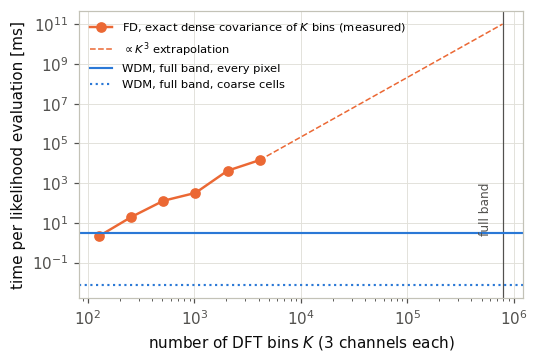

In [13]:
@jax.jit
def dense_gauss(S, x):
    Lc = jnp.linalg.cholesky(S)
    y = jax.scipy.linalg.solve_triangular(Lc, x, lower=True)
    return -jnp.vdot(y, y).real - 2 * jnp.sum(jnp.log(jnp.abs(jnp.diag(Lc))))


timing_dense = {}
k0 = int(1e-3 / grid.df)
for K in (128, 256, 512, 1024, 2048, 4096):
    S = aw.fd_dense_cov(k0, K, grid, dn, tnodes, window, aw.A_TRUE, aw.P_TRUE, Q=8)
    x = jnp.asarray(Xf2[:, k0:k0 + K].T.reshape(-1))
    Sj = jnp.asarray(S)
    dense_gauss(Sj, x).block_until_ready()
    t0 = time.perf_counter(); nrep = 5
    for _ in range(nrep):
        dense_gauss(Sj, x).block_until_ready()
    timing_dense[K] = (time.perf_counter() - t0) / nrep
    print(f"K = {K:5d} bins (matrix {3*K}x{3*K}): {1e3*timing_dense[K]:9.2f} ms per evaluation")

Ks = np.array(sorted(timing_dense)); ts = np.array([timing_dense[k] for k in Ks])
slope = np.polyfit(np.log(Ks[-3:]), np.log(ts[-3:]), 1)[0]
K_full = cells2.kedges()[-1] - cells2.kedges()[0]
t_full = ts[-1] * (K_full / Ks[-1]) ** 3
mem_full = (3 * K_full) ** 2 * 16 / 1e12
print(f"measured scaling ~ K^{slope:.2f}; full band K = {K_full}: extrapolated (K^3) "
      f"{t_full:.2e} s = {t_full/3.156e7:.1f} yr per evaluation, dense matrix {mem_full:.0f} TB")

# fine-grained (no coarse graining) WDM and FD block-diagonal likelihoods, for reference
nb = M_HI + 1 - M_LO
nt_in = grid.nt - 2 * EDGE
Yfine = jnp.asarray(np.tile(np.eye(3), (nt_in, nb, 1, 1)) * 1.0)
Ufine = jnp.asarray(np.tile(np.eye(3), (nt_in, nb, 1, 1)) * 0.1)
ll_wfine = aw.make_loglik_full(Yfine, np.ones((nt_in, nb)), Ufine, Ufine, complex_data=False)
Ifine = jnp.asarray(np.tile(np.eye(3), (K_full, 1, 1)) * (1 + 0j))
Uc = jnp.asarray(np.tile(np.eye(3), (K_full, 1, 1)) * (0.1 + 0j))
ll_ffine = aw.make_loglik_full(Ifine, np.ones(K_full), Uc, Uc, complex_data=True)
TIMING = dict(
    wdm_cells=SUMMARY["A2: WDM, local 3x3"]["t_eval_ms"],
    fd_cells=SUMMARY["A2: FD, time-averaged 3x3"]["t_eval_ms"],
    wdm_fine=1e3 * aw.time_loglik(ll_wfine, THETA_TRUE, nrep=5),
    fd_fine_blockdiag=1e3 * aw.time_loglik(ll_ffine, THETA_TRUE, nrep=5),
    fd_dense_extrapolated_s_per_point=t_full, fd_dense_scaling=slope,
    fd_dense_measured_ms={int(k): 1e3 * v for k, v in timing_dense.items()},
    K_full=int(K_full), n_wdm_pixels=int(nt_in * nb), dense_memory_TB=mem_full)
print(json.dumps({k: v for k, v in TIMING.items() if k != "fd_dense_measured_ms"}, indent=1))

fig, ax = plt.subplots(figsize=(5.0, 3.4))
ax.loglog(Ks, 1e3 * ts, "o-", color=COL["fd"], label="FD, exact dense covariance of $K$ bins (measured)")
Kx = np.geomspace(Ks[-1], K_full, 20)
ax.loglog(Kx, 1e3 * ts[-1] * (Kx / Ks[-1]) ** 3, color=COL["fd"], ls="--", lw=1.0, label=r"$\propto K^3$ extrapolation")
ax.axvline(K_full, color=COL["ink"], lw=0.8)
ax.text(K_full * 0.8, 1e3 * ts[0], "full band", rotation=90, ha="right", va="bottom", fontsize=8, color=COL["ink"])
ax.axhline(TIMING["wdm_fine"] / 32, color=COL["wdm"], lw=1.4, label="WDM, full band, every pixel")
ax.axhline(TIMING["wdm_cells"] / 32, color=COL["wdm"], ls=":", lw=1.4, label="WDM, full band, coarse cells")
ax.set_xlabel("number of DFT bins $K$ (3 channels each)"); ax.set_ylabel("time per likelihood evaluation [ms]")
ax.legend(fontsize=7.5, loc="upper left"); fig.tight_layout(); fig.savefig(os.path.join(FIG, "cost_scaling.pdf")); plt.show()

### 2c'. Is the time-averaged FD likelihood calibrated?

The block-diagonal FD likelihood with the time-averaged model has the right expectation, but
the true covariance of the DFT bins is not block-diagonal (Sec. 2b).  For Gaussian data the
maximum-likelihood estimator of a misspecified covariance model has the *sandwich* covariance
$H^{-1}JH^{-1}$, with $H$ the Fisher matrix of the model and
$J_{ij}=\sum_k\sum_q \mathrm{tr}(C^{-1}\partial_iC\,C^{-1}\hat C_q\,C^{-1}\partial_jC\,C^{-1}\hat C_q^\dagger)$
the actual variance of its score.  If $J=H$ the reported errors are right.

In [14]:
H_fd, J_fd, S_fd = aw.fd_sandwich(cells2, dn, tnodes, window, stride=64, qmax=12)
sig_model = np.sqrt(np.diag(np.linalg.inv(H_fd))); sig_true = np.sqrt(np.diag(S_fd))
CALIB = dict(fd_avg_reported_sigma=sig_model.tolist(), fd_avg_true_sigma=sig_true.tolist(),
             ratio=(sig_true / sig_model).tolist(),
             wdm_local_sigma_mcmc=SUMMARY["A2: WDM, local 3x3"]["std"],
             fd_avg_sigma_mcmc=SUMMARY["A2: FD, time-averaged 3x3"]["std"])
print("FD time-averaged: reported sigma (A, P) =", sig_model.round(5), " true scatter =", sig_true.round(5),
      " -> ratio", (sig_true / sig_model).round(3))
print("WDM local posterior sigma (A, P) =", np.round(SUMMARY["A2: WDM, local 3x3"]["std"], 5))

FD time-averaged: reported sigma (A, P) = [0.00396 0.00539]  true scatter = [0.00435 0.0054 ]  -> ratio [1.099 1.001]
WDM local posterior sigma (A, P) = [0.00413 0.0054 ]


### 2d. Explicit estimate: validity of the frozen-arm (analytic) covariance in FD vs WDM

Let $C(f,t)$ be the closed-form covariance with the arms at time $t$.
* **FD** uses one covariance for the whole observation; its error is the variation
  of $C$ over $T_{\rm obs}$: $\delta_{\rm FD}(f) = \max_t |C(f,t)-\bar C(f)|/\bar C(f)$.
* **WDM** uses $C(f_m,t_n)$ in each pixel; the error is the variation *within one atom*,
  $\delta_{\rm WDM}\simeq\tfrac12\sigma_t^2\,|\partial_t^2 C|/C$, with $\sigma_t\simeq0.85\,\Delta T$ the
  rms duration of the WDM atom.  For a variation dominated by the annual harmonic,
  $\delta_{\rm WDM}/\delta_{\rm FD}\simeq\tfrac12(\sigma_t\Omega)^2$, $\Omega=2\pi/{\rm yr}$.

sigma_t = 2.43 h,  (sigma_t Omega)^2/2 = 1.51e-06
{
 "sigma_t_over_dT": 0.8528884159111436,
 "half_sigmaOmega2": 1.511841114242865e-06,
 "delta_fd_max": {
  "A": 0.051700239588842775,
  "E": 0.04939602761954714,
  "T": 1.5981813110362733
 },
 "delta_wdm_max": {
  "A": 1.824076683994731e-07,
  "E": 9.992106488672824e-08,
  "T": 0.00010144624673603841
 },
 "delta_fd_at_1mHz": {
  "A": 0.023117436108863024,
  "E": 0.022519609168018893,
  "T": 0.46968824117819286
 },
 "delta_wdm_at_1mHz": {
  "A": 6.841996189081185e-08,
  "E": 5.350044318193589e-08,
  "T": 1.9790031613469616e-06
 },
 "max_abs_rho_TE_local": 0.9995234229451904,
 "max_abs_rho_TE_avg": 0.3215399796623546
}


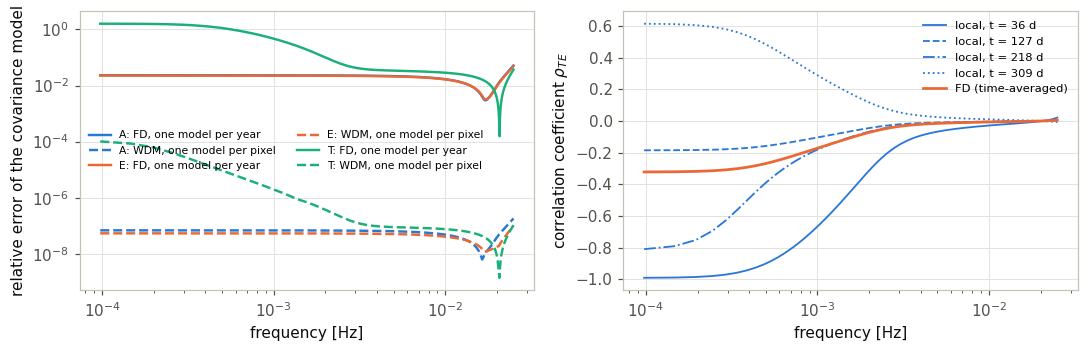

In [15]:
sig_t = aw.wdm_atom_time_spread() * grid.delta_t
Om = 2 * np.pi / aw.YEAR
print(f"sigma_t = {sig_t/3600:.2f} h,  (sigma_t Omega)^2/2 = {0.5*(sig_t*Om)**2:.2e}")
nodes_C = aw.A_TRUE**2 * surf["nodes_tm"] + aw.P_TRUE**2 * surf["nodes_oms"]   # (node, band, 3, 3)
fb = np.arange(M_LO, M_HI + 1) * grid.delta_f
inside = (tnodes >= 0) & (tnodes <= grid.T)
diag = np.einsum("tbii->tbi", nodes_C)[inside]                                 # (t, band, 3)
cbar = diag.mean(0)
delta_fd = np.max(np.abs(diag - cbar[None]) / cbar[None], axis=0)
spl = CubicSpline(tnodes, np.einsum("tbii->tbi", nodes_C), axis=0)
d2 = spl(tnodes[inside], 2)
delta_wdm = np.max(0.5 * sig_t**2 * np.abs(d2) / diag, axis=0)
rho_te_loc = nodes_C[inside][..., 1, 2] / np.sqrt(nodes_C[inside][..., 1, 1] * nodes_C[inside][..., 2, 2])
cavg = nodes_C[inside].mean(0)
rho_te_avg = cavg[:, 1, 2] / np.sqrt(cavg[:, 1, 1] * cavg[:, 2, 2])
ESTIMATE = dict(sigma_t_over_dT=sig_t / grid.delta_t, half_sigmaOmega2=0.5 * (sig_t * Om) ** 2,
                delta_fd_max={c: float(delta_fd[:, i].max()) for i, c in enumerate("AET")},
                delta_wdm_max={c: float(delta_wdm[:, i].max()) for i, c in enumerate("AET")},
                delta_fd_at_1mHz={c: float(np.interp(1e-3, fb, delta_fd[:, i])) for i, c in enumerate("AET")},
                delta_wdm_at_1mHz={c: float(np.interp(1e-3, fb, delta_wdm[:, i])) for i, c in enumerate("AET")},
                max_abs_rho_TE_local=float(np.abs(rho_te_loc).max()),
                max_abs_rho_TE_avg=float(np.abs(rho_te_avg).max()))
print(json.dumps(ESTIMATE, indent=1))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
for i, (ch, c) in enumerate(zip("AET", (COL["wdm"], COL["fd"], COL["ctl"]))):
    ax[0].loglog(fb, delta_fd[:, i], color=c, label=f"{ch}: FD, one model per year")
    ax[0].loglog(fb, delta_wdm[:, i], color=c, ls="--", label=f"{ch}: WDM, one model per pixel")
ax[0].set_xlabel("frequency [Hz]"); ax[0].set_ylabel("relative error of the covariance model")
ax[0].legend(fontsize=7, ncol=2)
for tt, ls in zip((0.1, 0.35, 0.6, 0.85), ("-", "--", "-.", ":")):
    it = np.argmin(np.abs(tnodes[inside] - tt * grid.T))
    ax[1].semilogx(fb, rho_te_loc[it], color=COL["wdm"], ls=ls, lw=1.2, label=f"local, t = {tt*grid.T/86400:.0f} d")
ax[1].semilogx(fb, rho_te_avg, color=COL["fd"], lw=1.8, label="FD (time-averaged)")
ax[1].set_xlabel("frequency [Hz]"); ax[1].set_ylabel(r"correlation coefficient $\rho_{TE}$")
ax[1].legend(fontsize=7.5)
fig.tight_layout(); fig.savefig(os.path.join(FIG, "fd_vs_wdm_estimate.pdf")); plt.show()

## 3. Analysis 3 — standard equal-arm diagonal $AET$ model in FD

Same ESA-orbit data as Analysis 2.  FD is fitted with the textbook model: diagonal
$AET$ covariance, equal arms (mean light travel time of the year).  WDM keeps the
local closed-form model.  As a control we also fit WDM with the equal-arm diagonal
model, to separate the effect of the *model* from that of the *domain*.

In [16]:
L_mean = float(np.mean(ltt_esa(np.linspace(0, grid.T, 400))))
fe_tm, fe_oms = aw.fd_model_equal_arm(cells2, L_mean)
we_tm, we_oms = aw.wdm_model_equal_arm(cells2, L_mean)
ll3_fd = aw.make_loglik_diag(I2, K2, fe_tm, fe_oms, complex_data=True)
ll3_wd_eq = aw.make_loglik_diag(Y2, D2, we_tm[None], we_oms[None], complex_data=False)
s3_fd = fit("A3: FD, equal-arm diag AET", ll3_fd)
s3_wdq = fit("A3: WDM, equal-arm diag AET", ll3_wd_eq)
ll3_fd_ae = aw.make_loglik_diag(I2, K2, fe_tm, fe_oms, complex_data=True, channels=(0, 1))
s3_fd_ae = fit("A3: FD, equal-arm diag AE only", ll3_fd_ae)

A3: FD, equal-arm diag AET   A = 2.6559 ± 0.0039  P = 18.7405 ± 0.0065   bias/σ = (-87.33, +579.91)   eval   0.04 ms / 32 walkers, MCMC   1.0 s, acc 0.68, acl 18


A3: WDM, equal-arm diag AET  A = 2.6589 ± 0.0039  P = 18.6967 ± 0.0065   bias/σ = (-86.37, +565.52)   eval   0.79 ms / 32 walkers, MCMC   2.5 s, acc 0.68, acl 19


A3: FD, equal-arm diag AE only A = 2.9992 ± 0.0042  P = 15.0087 ± 0.0068   bias/σ = ( -0.19,  +1.28)   eval   0.03 ms / 32 walkers, MCMC   0.9 s, acc 0.68, acl 19


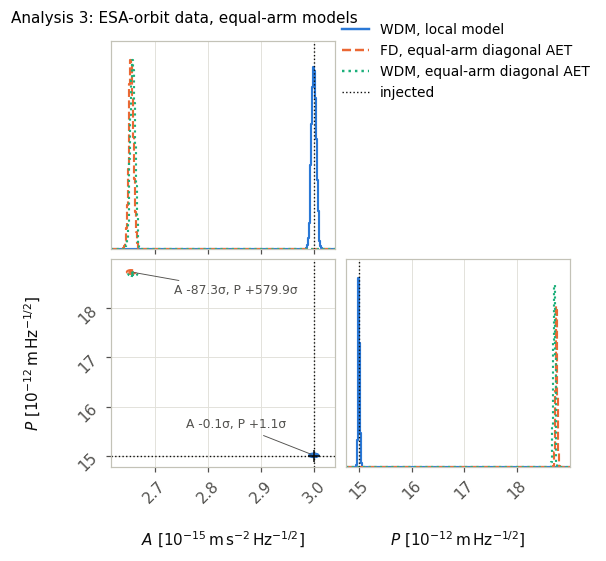

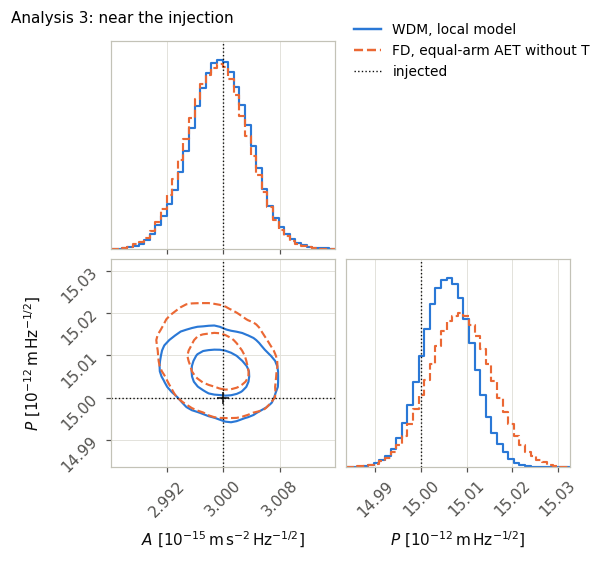

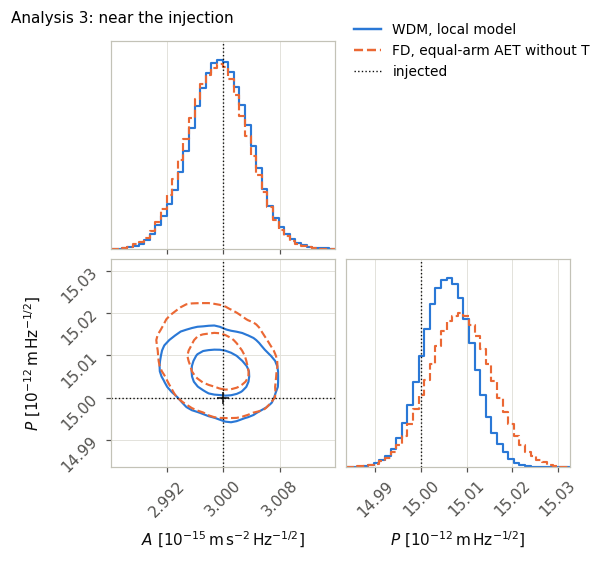

In [17]:
allS = np.concatenate([s3_fd, s2_wd, s3_wdq])
lo3, hi3 = allS.min(0), allS.max(0); pad3 = 0.06 * (hi3 - lo3)
rng3 = [(lo3[i] - pad3[i], hi3[i] + pad3[i]) for i in range(2)]
f3 = corner_overlay([(s2_wd, "WDM, local model", COL["wdm"], "-"),
                     (s3_fd, "FD, equal-arm diagonal AET", COL["fd"], "--"),
                     (s3_wdq, "WDM, equal-arm diagonal AET", COL["ctl"], ":")],
                    "corner_analysis3.pdf", title="Analysis 3: ESA-orbit data, equal-arm models",
                    ranges=rng3, bins=250, show=False)
ax2d = f3.axes[2]
for key, s_, off in (("A3: FD, equal-arm diag AET", s3_fd, (0.08, -0.45)), ("A2: WDM, local 3x3", s2_wd, (-0.24, 0.55))):
    b = SUMMARY[key]["bias_sigma"]
    m_ = s_.mean(0)
    ax2d.annotate(f"A {b[0]:+.1f}σ, P {b[1]:+.1f}σ", xy=m_, xytext=(m_[0] + off[0], m_[1] + off[1]),
                  fontsize=8, color=COL["ink"], arrowprops=dict(arrowstyle="-", color=COL["ink"], lw=0.6))
f3.savefig(os.path.join(FIG, "corner_analysis3.pdf"), bbox_inches="tight"); plt.show()
corner_overlay([(s2_wd, "WDM, local model", COL["wdm"], "-"),
                (s3_fd_ae, "FD, equal-arm AET without T", COL["fd"], "--")],
               "corner_analysis3_zoom.pdf", title="Analysis 3: near the injection")

f =  0.098 mHz: T data / equal-arm model =   528.98,  / unequal-arm model = 0.983;  A data / equal-arm = 1.0066
f =  0.293 mHz: T data / equal-arm model =    11.80,  / unequal-arm model = 0.972;  A data / equal-arm = 1.0203
f =  1.025 mHz: T data / equal-arm model =     1.38,  / unequal-arm model = 1.004;  A data / equal-arm = 0.9863
f =  2.929 mHz: T data / equal-arm model =     0.98,  / unequal-arm model = 0.966;  A data / equal-arm = 0.9806


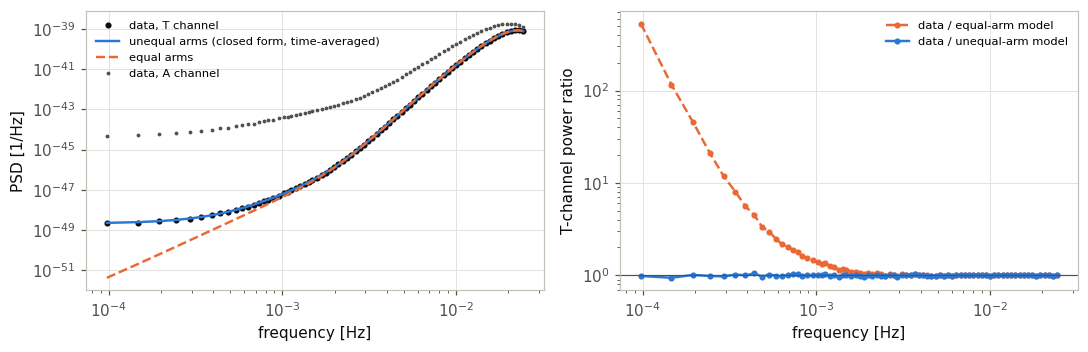

In [18]:
fc = cells2.fcentres()
Pd = np.real(np.einsum("cii->ci", I2))
Ceq = aw.A_TRUE**2 * fe_tm + aw.P_TRUE**2 * fe_oms
Cav = np.real(np.einsum("cii->ci", C_avg))
for fx in (1e-4, 3e-4, 1e-3, 3e-3):
    i = np.argmin(np.abs(fc - fx))
    print(f"f = {fc[i]*1e3:6.3f} mHz: T data / equal-arm model = {Pd[i, 2] / Ceq[i, 2]:8.2f},"
          f"  / unequal-arm model = {Pd[i, 2] / Cav[i, 2]:.3f};  A data / equal-arm = {Pd[i, 0] / Ceq[i, 0]:.4f}")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
ax[0].loglog(fc, Pd[:, 2], color="#0b0b0b", lw=0, marker="o", ms=3, label="data, T channel")
ax[0].loglog(fc, Cav[:, 2], color=COL["wdm"], label="unequal arms (closed form, time-averaged)")
ax[0].loglog(fc, Ceq[:, 2], color=COL["fd"], ls="--", label="equal arms")
ax[0].loglog(fc, Pd[:, 0], color=COL["ink"], lw=0, marker=".", ms=3, label="data, A channel")
ax[0].set_xlabel("frequency [Hz]"); ax[0].set_ylabel("PSD [1/Hz]"); ax[0].legend(fontsize=7.5)
ax[1].loglog(fc, Pd[:, 2] / Ceq[:, 2], color=COL["fd"], ls="--", marker="o", ms=3, label="data / equal-arm model")
ax[1].loglog(fc, Pd[:, 2] / Cav[:, 2], color=COL["wdm"], marker="o", ms=3, label="data / unequal-arm model")
ax[1].axhline(1, color=COL["ink"], lw=0.8)
ax[1].set_xlabel("frequency [Hz]"); ax[1].set_ylabel("T-channel power ratio"); ax[1].legend(fontsize=7.5)
fig.tight_layout(); fig.savefig(os.path.join(FIG, "tchannel_mismatch.pdf")); plt.show()

## 4. Summary

In [19]:
rows = []
for k, v in SUMMARY.items():
    rows.append(f"{k:32s} A = {v['mean'][0]:8.4f} ± {v['std'][0]:.4f} ({v['bias_sigma'][0]:+7.1f}σ)   "
                f"P = {v['mean'][1]:8.4f} ± {v['std'][1]:.4f} ({v['bias_sigma'][1]:+7.1f}σ)   "
                f"{v['t_eval_ms']:6.2f} ms/eval  {v['t_mcmc_s']:5.1f} s MCMC")
print("\n".join(rows))
with open(os.path.join(RES, "summary.json"), "w") as fh:
    json.dump(dict(posteriors=SUMMARY, timing=TIMING, estimate=ESTIMATE, fd_calibration=CALIB, mc_analysis1=MC,
                   grid=dict(dt=grid.dt, nt=grid.nt, nf=grid.nf, band_mHz=[M_LO * grid.delta_f * 1e3, M_HI * grid.delta_f * 1e3],
                             n_fcell=len(medges) - 1, n_tcell=N_TCELL)), fh, indent=1)
np.savez(os.path.join(RES, "chains.npz"), s1_fd=s1_fd, s1_wd=s1_wd, s2_wd=s2_wd, s2_fd=s2_fd, s2_fz=s2_fz,
         s3_fd=s3_fd, s3_wdq=s3_wdq, s3_fd_ae=s3_fd_ae)

A1: FD, diagonal AET             A =   3.0047 ± 0.0042 (   +1.1σ)   P =  15.0077 ± 0.0053 (   +1.4σ)     0.05 ms/eval    2.5 s MCMC
A1: WDM, diagonal AET            A =   3.0047 ± 0.0042 (   +1.1σ)   P =  15.0074 ± 0.0053 (   +1.4σ)     0.57 ms/eval    2.4 s MCMC
A2: WDM, local 3x3               A =   2.9995 ± 0.0041 (   -0.1σ)   P =  15.0059 ± 0.0054 (   +1.1σ)     0.23 ms/eval    1.8 s MCMC
A2: FD, time-averaged 3x3        A =   2.9983 ± 0.0039 (   -0.4σ)   P =  15.0052 ± 0.0054 (   +1.0σ)     0.06 ms/eval    0.9 s MCMC
A2: FD, frozen arms 3x3          A =   2.6636 ± 0.0039 (  -85.7σ)   P =  18.4188 ± 0.0064 ( +533.8σ)     0.07 ms/eval    1.0 s MCMC
A3: FD, equal-arm diag AET       A =   2.6559 ± 0.0039 (  -87.3σ)   P =  18.7405 ± 0.0065 ( +579.9σ)     0.04 ms/eval    1.0 s MCMC
A3: WDM, equal-arm diag AET      A =   2.6589 ± 0.0039 (  -86.4σ)   P =  18.6967 ± 0.0065 ( +565.5σ)     0.79 ms/eval    2.5 s MCMC
A3: FD, equal-arm diag AE only   A =   2.9992 ± 0.0042 (   -0.2σ)   P =  15.

## 5. What the three analyses show

* **Analysis 1 (equal arms, stationary).**  FD and WDM give the same posterior on $(A,P)$ — here
  $A=3.0047\pm0.0042$ in both, $P=15.0077$ vs $15.0074\pm0.0053$ — and over 52 independent realisations
  (`mc_bias_check.py`) both are unbiased and calibrated and agree realisation by realisation to $0.04\sigma$ rms.
* **Analysis 2 (ESA orbits).**  The WDM likelihood with the closed-form covariance evaluated *with the arms at
  the time of each pixel* is unbiased ($-0.1\sigma$, $+1.1\sigma$).  In FD the Fourier bins are correlated (up to
  60% at lag 1 in $T$ below 0.2 mHz), so the exact likelihood needs a dense covariance: 16 s per evaluation for
  4096 bins already, months to years for the full band (89 TB).  The block-diagonal FD shortcuts are fast but
  either biased by hundreds of σ (arms frozen at mid-year) or unbiased with a 10% over-confident error on $A$
  (yearly-averaged model: the local redundancy between $T$ and $E$ is lost).  So: yes, WDM is much faster than
  the *correct* FD analysis.  The WDM covariance is diagonal in the pixels and, in the fixed basis of
  `diagonal_likelihood.ipynb` (the TM covariance is 4× the OMS one up to a diagonal term, so one basis per pixel
  diagonalises it for every $A$, $P$), also in the channels: no 3×3 algebra and no parameter-dependent rotation.
* **Analysis 3 (standard equal-arm diagonal AET in FD).**  Biased by $-87\sigma$ in $A$ and $+580\sigma$ in $P$; the
  same model in WDM is equally biased, so the cure is the local model, not the domain.  The bias comes from the
  null channel ($T$ power 529× the equal-arm prediction at 0.1 mHz); dropping $T$ removes it at the price of a
  26% larger error on $P$.